
# Predição da faixa de preço de carros usados no Reino Unido (MLPClassifier)

**AT2 – Redes Neurais**

Notebook de exploração, treinamento e exportação do modelo.



## 1. Contexto do Problema e Dicionário de Dados

**Origem do dataset:** Used Cars UK (Kaggle), com anúncios de carros usados no Reino Unido (arquivo `data/dataset.csv`).

**Objetivo de negócio:** uma revendedora ou um comprador precisa saber rapidamente em que faixa de preço um carro usado se encaixa, a partir de características básicas do anúncio (marca, quilometragem, ano, motor etc.).

**Definição do problema:** classificação multiclasse. A coluna original `Price` (libras, £) é contínua e foi discretizada em três classes:

| Classe | Regra |
|---|---|
| Economico | Até £3.000 |
| Intermediario | De £3.000 até £6.500 |
| Premium | Acima de £6.500 |

A coluna `Price` não será usada como atributo preditor, evitando vazamento de dados.

### Dicionário de dados

| Coluna | Tipo | Significado |
|---|---|---|
| marca | Categórica | Fabricante do veículo |
| quilometragem | Numérica | Milhas rodadas |
| ano_registro | Numérica | Ano de registro |
| numero_donos | Numérica | Donos anteriores |
| combustivel | Categórica | Tipo de combustível |
| carroceria | Categórica | Tipo de carroceria |
| motor_litros | Numérica | Cilindrada em litros |
| cambio | Categórica | Manual ou automático |
| portas | Numérica | Quantidade de portas |
| assentos | Numérica | Quantidade de assentos |
| classe_emissao | Categórica | Padrão Euro de emissões |
| historico_completo | Numérica | Histórico de manutenção completo (0/1) |
| faixa_preco | Alvo | Classe de preço |



## 2. Análise Exploratória Resumida


In [13]:

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    matthews_corrcoef,
    ConfusionMatrixDisplay
)

SEED = 77

DATA_PATH = Path(r'C:\Users\PC\Desktop\am-at2-redes-neurais\data\dataset.csv')
MODEL_PATH = Path('../models/pipeline_rede_neural.joblib')

sns.set_theme(style='whitegrid')


In [14]:

df_raw = pd.read_csv(DATA_PATH)

print('Dimensão (linhas, colunas):', df_raw.shape)

df_raw.head()


Dimensão (linhas, colunas): (3685, 14)


,Unnamed: 0,title,Price,Mileage(miles),Registration_Year,Previous Owners,Fuel type,Body type,Engine,Gearbox,Doors,Seats,Emission Class,Service history
0,0,SKODA Fabia,6900,70189,2016,3.0,Diesel,Hatchback,1.4L,Manual,5.0,5.0,Euro 6,NaN
1,1,Vauxhall Corsa,1495,88585,2008,4.0,Petrol,Hatchback,1.2L,Manual,3.0,5.0,Euro 4,Full
2,2,Hyundai i30,949,137000,2011,NaN,Petrol,Hatchback,1.4L,Manual,5.0,5.0,Euro 5,NaN
3,3,MINI Hatch,2395,96731,2010,5.0,Petrol,Hatchback,1.4L,Manual,3.0,4.0,Euro 4,Full
4,4,Vauxhall Corsa,1000,85000,2013,NaN,Diesel,Hatchback,1.3L,Manual,5.0,5.0,Euro 5,NaN


In [15]:

nulos = df_raw.isna().sum().to_frame('nulos')

nulos['% nulos'] = (
    nulos['nulos'] / len(df_raw) * 100
).round(1)

nulos[nulos['nulos'] > 0]


,nulos,% nulos
Previous Owners,1409,38.2
Engine,45,1.2
Doors,25,0.7
Seats,35,0.9
Emission Class,87,2.4
Service history,3145,85.3



**Achados:**

As colunas `Service history` (85% vazio), `Previous Owners` (38%) e, em menor grau, `Emission Class`, `Engine`, `Seats` e `Doors` apresentam valores ausentes.

Em `Service history`, o único valor existente é `Full`. Assim, a ausência significa histórico não informado.

Os demais valores ausentes serão tratados por imputação dentro do Pipeline, garantindo que as estatísticas sejam aprendidas somente com os dados de treinamento.



### Limpeza e Engenharia de Atributos


In [16]:

MARCAS_COMPOSTAS = {
    'Land': 'Land Rover',
    'Alfa': 'Alfa Romeo'
}

df = pd.DataFrame({
    'marca': df_raw['title'].str.split().str[0].replace(MARCAS_COMPOSTAS),
    'quilometragem': df_raw['Mileage(miles)'],
    'ano_registro': df_raw['Registration_Year'],
    'numero_donos': df_raw['Previous Owners'],
    'combustivel': df_raw['Fuel type'],
    'carroceria': df_raw['Body type'],
    'motor_litros': df_raw['Engine'].str.replace('L', '', regex=False).astype(float),
    'cambio': df_raw['Gearbox'],
    'portas': df_raw['Doors'],
    'assentos': df_raw['Seats'],
    'classe_emissao': df_raw['Emission Class'],
    'historico_completo': df_raw['Service history'].eq('Full').astype(int),
    'preco': df_raw['Price']
})

n0 = len(df)

# Remoção de valores extremos
df = df[
    (df['quilometragem'] <= 300_000) &
    (df['ano_registro'] >= 1990)
]

# Remoção de duplicados
df = df.drop_duplicates().reset_index(drop=True)

print(f'Linhas: {n0} -> {len(df)}')

# Criação da variável alvo
df['faixa_preco'] = pd.cut(
    df['preco'],
    bins=[0, 3000, 6500, np.inf],
    labels=['Economico', 'Intermediario', 'Premium']
)

# Remoção do preço original
df = df.drop(columns='preco')

df.head()


Linhas: 3685 -> 2849


,marca,quilometragem,ano_registro,numero_donos,combustivel,carroceria,motor_litros,cambio,portas,assentos,classe_emissao,historico_completo,faixa_preco
0,SKODA,70189,2016,3.0,Diesel,Hatchback,1.4,Manual,5.0,5.0,Euro 6,0,Premium
1,Vauxhall,88585,2008,4.0,Petrol,Hatchback,1.2,Manual,3.0,5.0,Euro 4,1,Economico
2,Hyundai,137000,2011,NaN,Petrol,Hatchback,1.4,Manual,5.0,5.0,Euro 5,0,Economico
3,MINI,96731,2010,5.0,Petrol,Hatchback,1.4,Manual,3.0,4.0,Euro 4,1,Economico
4,Vauxhall,85000,2013,NaN,Diesel,Hatchback,1.3,Manual,5.0,5.0,Euro 5,0,Economico



### Gráficos Essenciais


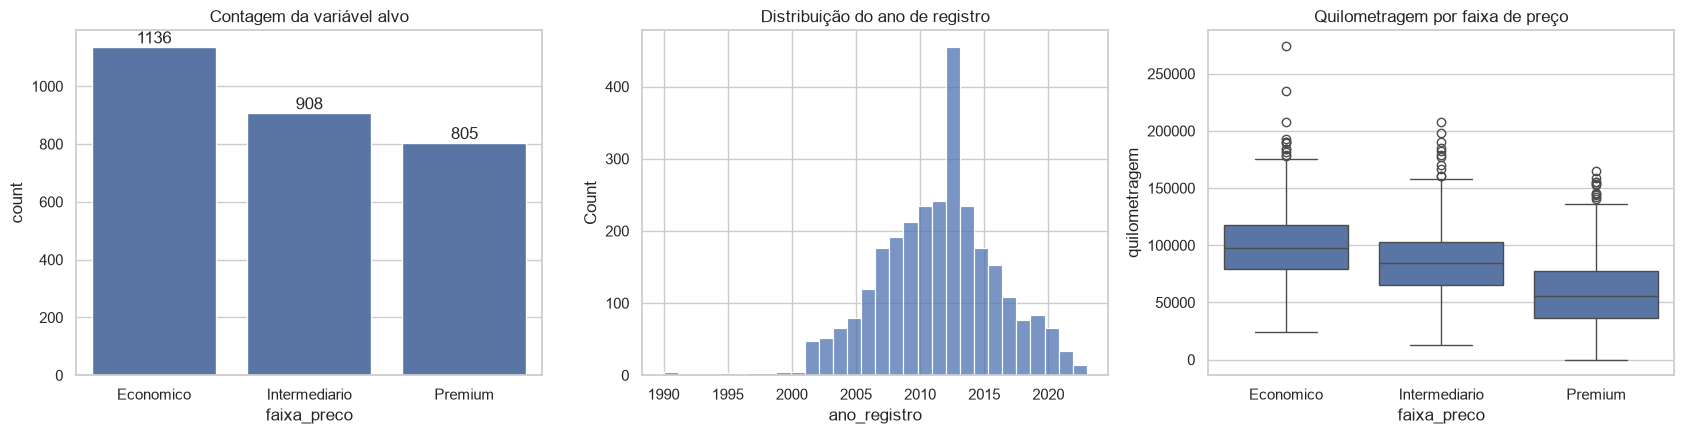

faixa_preco
Economico        0.399
Intermediario    0.319
Premium          0.283
Name: proportion, dtype: float64


In [17]:

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Balanceamento das classes
ordem = ['Economico', 'Intermediario', 'Premium']

sns.countplot(
    data=df,
    x='faixa_preco',
    order=ordem,
    ax=axes[0]
)

axes[0].set_title('Contagem da variável alvo')

for c in axes[0].containers:
    axes[0].bar_label(c)

# Distribuição dos anos
sns.histplot(
    df['ano_registro'],
    bins=30,
    ax=axes[1]
)

axes[1].set_title('Distribuição do ano de registro')

# Quilometragem por faixa
sns.boxplot(
    data=df,
    x='faixa_preco',
    y='quilometragem',
    order=ordem,
    ax=axes[2]
)

axes[2].set_title('Quilometragem por faixa de preço')

plt.tight_layout()
plt.show()

print(df['faixa_preco'].value_counts(normalize=True).round(3))



**Leitura dos gráficos:**

As classes apresentam uma distribuição que permite avaliar o desempenho do classificador.

Carros mais novos e com menor quilometragem tendem a pertencer às faixas de preço mais elevadas, indicando que esses atributos podem fornecer informações úteis para a rede neural.



## 3. Construção do Pipeline Scikit-Learn


In [18]:

NUMERICAS = [
    'quilometragem',
    'ano_registro',
    'numero_donos',
    'motor_litros',
    'portas',
    'assentos',
    'historico_completo'
]

CATEGORICAS = [
    'marca',
    'combustivel',
    'carroceria',
    'cambio',
    'classe_emissao'
]

X = df[NUMERICAS + CATEGORICAS]

y = df['faixa_preco'].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)


Treino: (2279, 12)
Teste: (570, 12)


In [19]:

preprocessador = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), NUMERICAS),

        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), CATEGORICAS)
    ]
)


In [20]:

mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    alpha=1e-3,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=SEED
)

pipeline = Pipeline([
    ('preprocessamento', preprocessador),
    ('mlp', mlp)
])

pipeline.fit(X_train, y_train)

print(
    'Iterações até convergir:',
    pipeline.named_steps['mlp'].n_iter_
)


Iterações até convergir: 37



## 4. Avaliação do Modelo


In [21]:

y_pred = pipeline.predict(X_test)

print(
    f'Acurácia global: {accuracy_score(y_test, y_pred):.4f}'
)

print(
    f'Matthews Corrcoef (MCC): {matthews_corrcoef(y_test, y_pred):.4f}'
)

print()

print(
    classification_report(y_test, y_pred, digits=3)
)


Acurácia global: 0.8281
Matthews Corrcoef (MCC): 0.7390

               precision    recall  f1-score   support

    Economico      0.849     0.890     0.869       227
Intermediario      0.749     0.720     0.734       182
      Premium      0.885     0.863     0.874       161

     accuracy                          0.828       570
    macro avg      0.828     0.824     0.826       570
 weighted avg      0.827     0.828     0.827       570



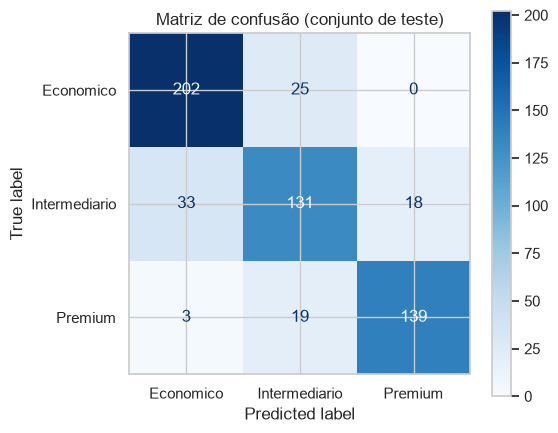

In [22]:

fig, ax = plt.subplots(figsize=(5.5, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=ordem,
    cmap='Blues',
    ax=ax
)

ax.set_title('Matriz de confusão (conjunto de teste)')

plt.show()



**Interpretação:**

O MCC (Matthews Correlation Coefficient), que varia de -1 a 1, resume a qualidade das previsões considerando todas as células da matriz de confusão.

Os erros podem ocorrer principalmente entre classes vizinhas (Econômico e Intermediário; Intermediário e Premium), pois carros próximos aos limites de preço apresentam características semelhantes.



## 5. Exportação do Modelo Treinado

O Pipeline completo será salvo, incluindo a rede neural e todas as etapas de pré-processamento.

Assim, o arquivo `.joblib` armazenará as estatísticas de imputação, escalonamento e categorias do One-Hot Encoding.


In [23]:

MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(pipeline, MODEL_PATH)

print('Pipeline salvo em:', MODEL_PATH.resolve())


Pipeline salvo em: C:\Users\PC\Desktop\am-at2-redes-neurais\models\pipeline_rede_neural.joblib


In [24]:

# Recarregar o modelo
modelo = joblib.load(MODEL_PATH)

# Criar exemplo de um carro
exemplo = pd.DataFrame([{
    'quilometragem': 60000,
    'ano_registro': 2016,
    'numero_donos': 2,
    'motor_litros': 1.6,
    'portas': 5,
    'assentos': 5,
    'historico_completo': 1,
    'marca': 'Ford',
    'combustivel': 'Petrol',
    'carroceria': 'Hatchback',
    'cambio': 'Manual',
    'classe_emissao': 'Euro 6'
}])

# Realizar previsão
proba = modelo.predict_proba(exemplo)[0]

classe = modelo.predict(exemplo)[0]

print('Faixa de preço prevista:', classe)

print('Confiança:', round(proba.max(), 4))


Faixa de preço prevista: Premium
Confiança: 0.9855
